# Regressionsanalyse

Wenn man einen Datensatz hinreichend aufbereitet hat (fehlende Daten ersetzt, geeignet reskaliert, neue Features definiert), kann man sich an eine Regressionsanalyse wagen. Bei einer Regression geht es darum, den Zusammenhang zwischen zwei Variablen zu beschreiben. Dabei soll eine Variable als abhängig von der anderen beschrieben werden, explizit durch die Angabe eines funktionalen Zusammenhangs, d.h. einer mathematischen Abbildung, die aus den Werten der einen Variable die Werte der anderen berechnet - näherungsweise.

Ein **Regressionsmodell** besteht aus:

* **Regressoren** $x_i$, das ist eine ($k$-variate) 'unabhängige' Variable, die *Einflussgröße*
* **Regressand** $y_i$, das ist eine (univariate) 'abhängige' Variable, die *Zielgröße*
* **Parametern** $\beta_1,\dots,\beta_k$
* **Störgrößen** $\epsilon_i$
* $Y_i = f(X_i, \beta) + \epsilon_i$

Für konkrete Daten $(x_i,y_i)$ nennt man $y_i - f(x_i, \beta)$ für ein gegebenes Regressionsmodell auch **das $i$-te Residuum**.

Eine Regressionsanalyse besteht darin, ein Regressionsmodell aufzustellen und dann die Funktion $f$ zu schätzen, die am besten zu den Daten passt, d.h. die kleinsten Residuen hat.

Bestimmte Regressionsverfahren unterscheiden sich in der Art der zulässigen Funktion $f$.
Bei der linearen Regression ist $f$ eine Funktion, die in den Parametern $\beta$ linear ist.

```{admonition} Beispiel
Der Einfachheit halber sei $k=1$, d.h. $X_i$ eine univariate Variable.
Wenn wir für $f$ die Klasse der konstanten Funktionen wählen, dann ist $f(X_i,\beta) = \beta_1$
und wir suchen das $\beta_1$, sodass $Y_i = \beta_1 + \epsilon_i$, also ein $\beta_1$, welches für alle Werte $y_i$ den Abstand $d(\beta_1, y_i) = y_i - \beta_1$ minimiert.
Das ist der Fall für $\texttt{mse}(y,\beta_1) = \frac{1}{n} \sum_{i=1}^n (y_i - \beta_1)^2$ minimal, d.h. $\beta_1 = \texttt{mean}(y)$.
```

```{admonition} Beispiel
Man kann k-Means als Regressionsverfahren sehen: die Parameter $\beta$ beschreiben die Orte der Zentroide und die Funktion $f$ ist die Auswahl einer Klasse in Abhängigkeit vom nächstgelegenen Zentroid. Das konkrete k-Means-Verfahren ist die Suche nach einer Näherung für optimale Parameter $\beta$.

Bei k-Means werden die Störgrößen normalverteilt ohne Korrelation angenommen.
```

```{admonition} Beispiel
Jedes Klassifikationsverfahren ist eine Regression, wobei die abhängige Variable die Klasse ist, die Regressoren alle Daten, die zur Klassifikation verwendet werden.
```

## Kleinste Quadrate

```{admonition} Definition
Wenn man in einem Regressionsmodell die **Residuenquadratsumme** $\sum_{i=1}^N {\left(Y_i - f(X_i,\beta)\right)}^2$ minimiert, spricht man von einem Schätzwert für $\beta$, der als **kleinste-Quadrate-Schätzer** bekannt ist.
```

Der kleinste-Quadrate-Schätzer ist ein Maximum-Likelihood-Schätzer.

```{admonition} Beispiel
Wenn wir zu Punkten $(x_i,y_i)$ in der Ebene eine Gerade berechnen,
die den gemeinsamen Abstand zu allen Punkten minimiert (eine sogenannte Ausgleichsgerade),
so ist dies genau eine Regression mit $f(x, \beta) = \beta_0 + \beta_1 x$.
Die Regressionsgleichung $Y_i = f(X_i, \beta)$ wird zur Geradengleichung
$y_i = \beta_0 + \beta_1 x_i$
wobei $\beta_0$ der y-Achsenabschnitt (bei $x_i=0$) und $\beta_1$ die Steigung der Geraden ist.

Die kleinste-Quadrate-Methode ist nun, $\beta_0$ und $\beta_1$ so zu schätzen,
dass $\sum_{i=1}^N {\left(y_i - \beta_1x_i - \beta_0  \right)}^2$ minimiert wird.

Wenn $\beta_0=0$ ist haben wir ein lösbares Minimierungsproblem.
Wir leiten nach $\beta_1$ ab und suchen Nullstellen:

$$
0 &= \sum_{i=1}^N 2{\left(y_i - \beta_1 x_i  \right)}{\left(- x_i  \right)} \\
  &= \sum_{i=1}^N 2 \left( \beta_1 x_i^2 - y_i x_i \right) \\
  &= 2\left(\beta_1 \sum_{i=1}^N x_i^2 - \sum_{i=1}^N x_iy_i \right)
$$

also ist $\beta_1 = \dfrac{\sum_{i=1}^N x_iy_i}{\sum_{i=1}^N x_i^2}$.
```

Im Allgemeinen lässt sich $\beta_0$ berechnen mit der Formel

$$
\beta_0 = \texttt{mean}(y) - \beta_1\texttt{mean}(x).
$$

Um also zunächst $\beta_1$ im Allgemeinen zu bestimmen, verschiebt man die Daten um die Mittelwerte, also ersetzt $x_i$ durch $x_i' = x_i - \texttt{mean}(x)$ und $y_i$ durch $y_i' = y_i - \texttt{mean}(y)$. Damit erhält man die Formel

$$
\beta_1 = \dfrac{\sum_{i=1}^N (x_i - \texttt{mean}(x))(y_i - \texttt{mean}(y))}{\sum_{i=1}^N (x_i - \texttt{mean}(x))^2}
$$


In [1]:
import numpy as np
np.random.seed(1234)

# generate synthetic data:
x = np.linspace(-2, 8)
y = x**2 + 3*x - 7 + np.random.uniform(-3, 3, size=x.shape)

# compute estimate from before:
x_centered = x - np.mean(x)
y_centered = y - np.mean(y)
beta_1 = ( x_centered.T @ y_centered ) / sum(np.square(x_centered))
beta_0 = np.mean(y) - beta_1*np.mean(x)
print("line equation is y = %f*x + %f" % (beta_1, beta_0))

line equation is y = 8.912806*x + -6.929693


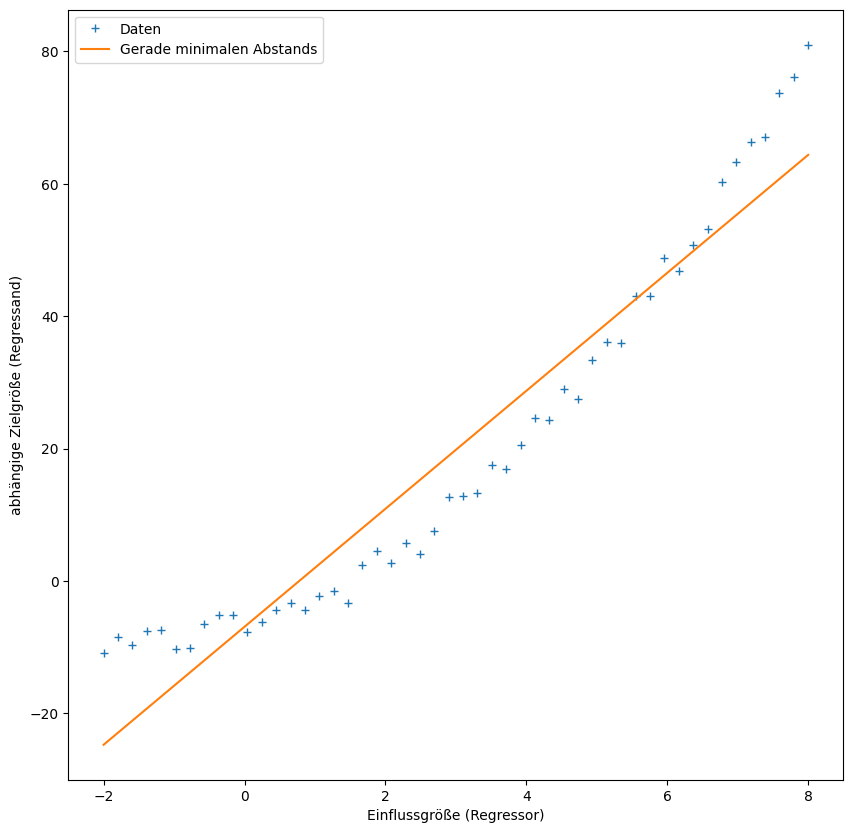

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10,10))
ax.plot(x, y, "+", label="Daten")
ax.plot(x, beta_0 + x*beta_1, label="Gerade minimalen Abstands")
ax.set_xlabel("Einflussgröße (Regressor)")
ax.set_ylabel("abhängige Zielgröße (Regressand)")
ax.legend()
plt.show()

Die Methode kleinster Quadrate lässt sich auch direkt mit Scipy nutzen (also muss man sich die Formeln oder die Herleitung nicht merken):

In [3]:
from scipy.optimize import curve_fit

# define function class for regression (linear):
def f(x, beta_0, beta_1):
    return beta_1*x + beta_0

# perform regression analysis:
parameters, covariance_matrix = curve_fit(f, x, y)
assert np.all(np.isclose((beta_0, beta_1), parameters))

Aus der Dokumentation von Scipy:

`scipy.optimize.curve_fit`
>
> Use non-linear least squares to fit a function, f, to data.
> 
> Assumes ydata = f(xdata, *params) + eps.

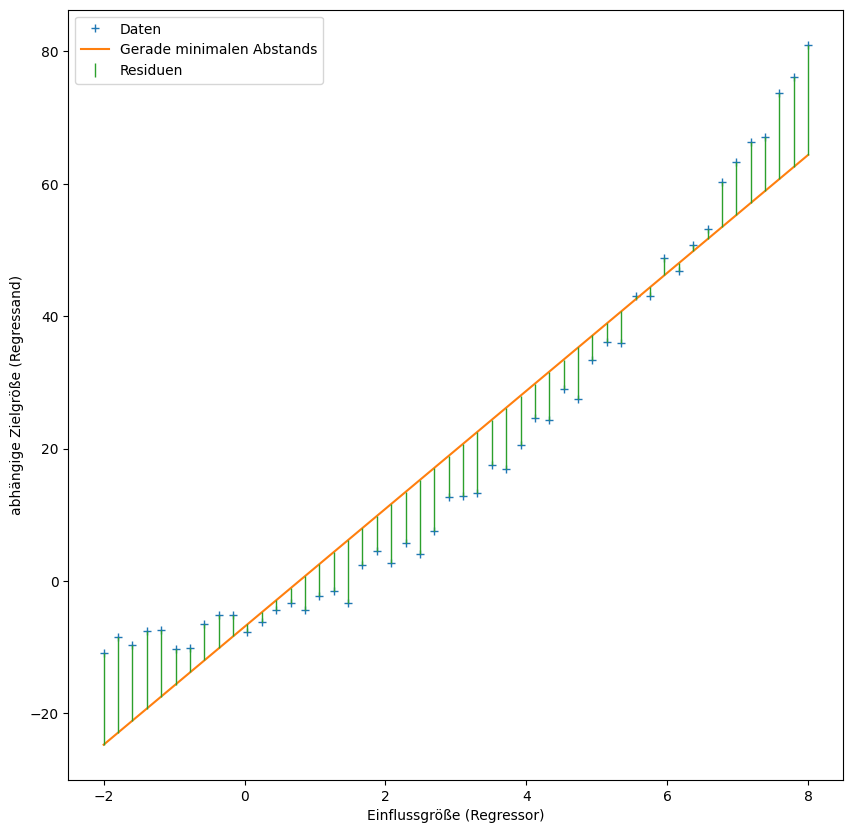

In [4]:
fig, ax = plt.subplots(figsize=(10,10))
ax.plot(x, y, "+", label="Daten")
ax.plot(x, f(x, beta_0, beta_1), label="Gerade minimalen Abstands")
yerr = np.stack((np.maximum(np.zeros_like(y), y - f(x, beta_0, beta_1)),
                 -np.minimum(np.zeros_like(y), y - f(x, beta_0, beta_1))))
ax.errorbar(x, y,
            yerr=yerr,
            linewidth=0, elinewidth=1,
            label="Residuen")
ax.set_xlabel("Einflussgröße (Regressor)")
ax.set_ylabel("abhängige Zielgröße (Regressand)")
ax.legend()
plt.show()

Bitte beachten Sie, dass dies nicht die Richtung maximaler Varianz ist - dabei werden zwar auch Abstände minimiert, aber eben die Abstände der Datenpunkte $(x,y)$ zur Geraden. Bei der linearen Regression werden nicht Abstände der Datenpunkte zur Geraden minimiert, sondern die Residuen, das sind die Abstände entlang der $y$-Achse. Im Plot oben ist das sichtbar: die grünen Striche sind parallel zur $y$-Achse, nicht senkrecht auf der Geraden (was dem Abstand zur Geraden entsprechen würde).

Damit ist auch klar, dass die Regression ein assymmetrisches Verfahren ist, in dem Sinne dass Regressor und Regressand nicht vertauscht werden können, ohne das Modell zu ändern. Bei der Suche nach einer Gerade entlang maximaler Varianz sind $x$- und $y$-Koordinaten gleichberechtigt und die Lösung invariant unter Drehungen.

## Lineare Regression

```{admonition} Definition
Eine Regression der Form $Y_i = f(X_i, w) + \epsilon_i$ mit $f(x, w) = w^T x$ heißt **lineare Regression**.
```

Dabei ist es üblich, stillschweigend den Vektor $x$ durch $(1,x)$ zu ersetzen, damit z.B. für $x = (a,b)$ gilt: $f(x,w)= w^T x = (w_0,w_1,w_2)\cdot(1,a,b) = w_0 + w_1 a + w_2 b$. Der $w_0$-Term (zuvor $\beta_0$ bezeichnet) heißt auch **Bias-Term**.

Eine einfache lineare Regression lässt sich mit Scipy.stats durchführen:

In [5]:
from scipy.stats import linregress

linregress_result = linregress(x, y)
slope, intercept, r, p, se = linregress_result
print("slope is %f" % slope)
assert np.isclose(slope, beta_1)
print("y-intercept is %f" % intercept)
assert np.isclose(intercept, beta_0)
print("correlation coefficient is %f" % r)
print("p-value is %.32f" % p)
print("squared error is %f" % se)

slope is 8.912806
y-intercept is -6.929693
correlation coefficient is 0.959514
p-value is 0.00000000000000000000000000046030
squared error is 0.377630


Scipy hat für uns gleich einen Test durchgeführt, nämlich einen beidseitigen Test mit der Nullhypothese, dass die Steigung `slope` gleich $0$ ist. Da der $p$-Wert deutlich kleiner als $\alpha = 0.05$ ist, verwerfen wir die Hypothese und gehen von einer Steigung $\neq 0$ aus. (Das benutzen wir jetzt einfach, ohne uns eingehender mit statistischen Tests auseinander zu setzen - oder wir ignorieren diesen Teil der Ausgabe von Scipy.stats).

```{admonition} Definition
Wenn eine Regressorvariable die Form $\phi(X_i)$ hat, für $\phi$ eine beliebige Funktion mit passendem Definitionsbereich, dann nennt man dies immer noch eine **lineare Regression mit Regressor $X_i$ und Basisfunktionserweiterung**.
```

Damit ist bei einer linearen Regression also nur eins linear: die Funktion $f$ in den Variablen $w$. So können wir das zuvor stillschweigende Ersetzen von $x$ durch $(1,x)$ auch als Basisfunktionserweiterung auffassen, mit $\phi(x) = (1,x)$.

Machen Sie sich klar, dass die zweite Definition keine Verallgemeinerung der ersten Definition ist.

Da die lineare Regressionsanalyse sehr einfach durchzuführen ist, wird die zentrale Frage bei der linearen Regression die Aufstellung des Modells, insbesondere der Basisfunktion anhand von Daten.

Man nennt den Fall $w = (w_0, w_1)$ eine **einfache lineare Regression** und den allgemeineren Fall dann eine **multilineare Regression**, weil dabei dann eine multivariate unabhängige Variable $X$ als Regressor verwendet wird. Die lineare Regression von Scipy.stats kann nur eine einfache lineare Regression!

Darum betrachten wir nun die multilineare Regression mit Scikit-learn:

In [6]:
from sklearn.linear_model import LinearRegression

# first look at linear, to compare with the above:
linear_regressor = LinearRegression()
linear_regressor.fit(x.reshape(-1, 1), y)
Y_pred = linear_regressor.predict(x.reshape(-1, 1)) 

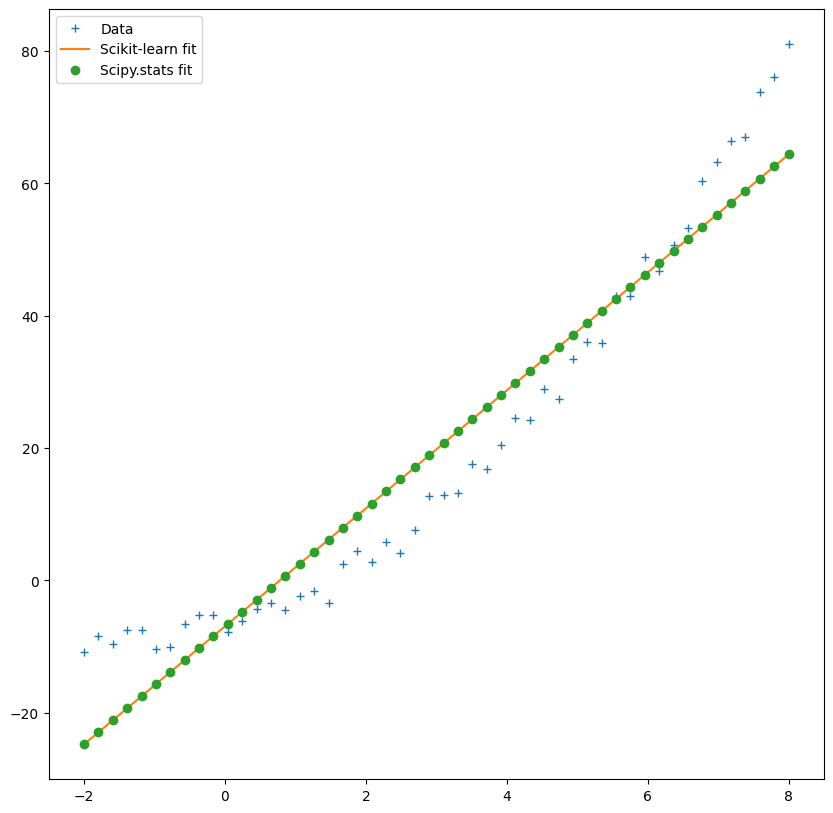

In [7]:
fig, ax = plt.subplots(figsize=(10,10))
ax.plot(x, y, "+", label="Data")
ax.plot(x, Y_pred, label="Scikit-learn fit")
ax.plot(x, f(x, beta_0, beta_1), "o", label="Scipy.stats fit")
ax.legend()
plt.show()

Aus der Scikit-learn-Dokumentation:

`sklearn.linear_model.LinearRegression`
>
> From the implementation point of view, this is just plain Ordinary Least Squares (scipy.linalg.lstsq) or Non Negative Least Squares (scipy.optimize.nnls) wrapped as a predictor object.

So gesehen ist Scikit-learn nicht 'besser' als Scipy, sondern einfach ein Layer oben drauf.

```{admonition} Beispiel
Die Nutzung der Basisfunktion $\phi(x) = (1,x,x^2,x^3,\dots,x^d)$ mit $d > 0$ nennt man **polynomiale Regression**.
Konkret für $d=2$ bedeutet dass, dass $f(x,w) = w_0 + w_1x + w_2x^2$ ist. Wir sehen nochmal deutlich: $f$ ist linear in $w$, nicht in $x$.
```

Ein Problem bei der Wahl einer Basisfunktion für ein Regressionsmodell ist das Overfitten. Wenn zu viele Parameter verfügbar sind, lassen sich die Daten zwar sehr gut fitten, aber das Modell verallgemeinert nicht gut. Konkret prüfen lässt sich das durch einen Fit auf einen Trainingsdatensatz, der dann auf einem Testdatensatz evaluiert wird.

```{admonition} Beispiel
Wir betrachten das Overfitten in Abhängigkeit vom Parameter $d$ der polynomialen Regression, auf dem gleichen Datensatz wie zuvor im Beispiel mit einer Regressionsgeraden (der Fall $d=1$).
```

In [8]:
# define basis function class
def phi(x, d):
    return np.dstack([np.power(x, i) for i in range(d+1)]).squeeze()

def plot_regression(x, y, Y_pred, ax, x_test=None, y_test=None):
    ax.plot(x, y, "+", label="Daten")
    if(x_test is None):
        x_test = x
    ax.plot(x_test, Y_pred, label="Modell")
    if(y_test is None):
        y_test = y
    yerr = np.stack(( np.maximum(np.zeros_like(y_test), y_test - Y_pred),
                     -np.minimum(np.zeros_like(y_test), y_test - Y_pred)))
    ax.errorbar(x_test, y_test,
                yerr=yerr,
                linewidth=0, elinewidth=1,
                label="Residuen")
    ax.set_xlabel("Einflussgröße (Regressor)")
    ax.set_ylabel("abhängige Zielgröße (Regressand)")
    ax.legend()
    return ax

def poly_regression_plot(x, y, d):
    # perform regression analysis:
    transformed_x = phi(x, d)

    linear_regressor = LinearRegression()
    linear_regressor.fit(transformed_x, y)
    Y_pred = linear_regressor.predict(transformed_x)
    
    fig, ax = plt.subplots(figsize=(10,10))
    plot_regression(x, y, Y_pred, ax).\
      set_title("Polynomiale Regression von Grad %d" % d)
    plt.show()

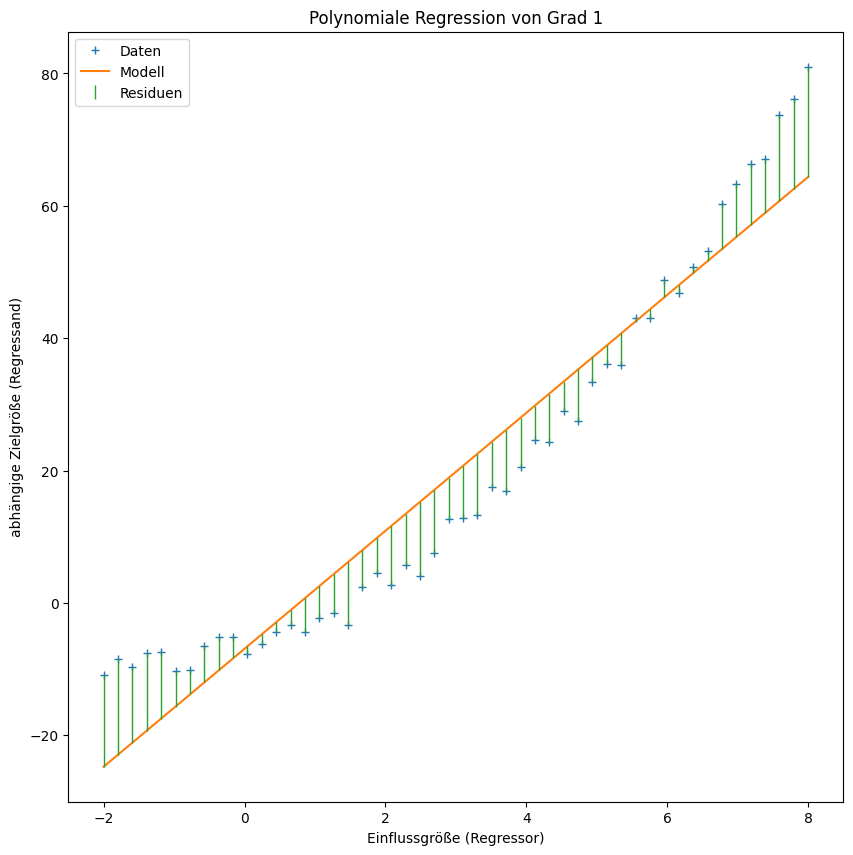

In [9]:
poly_regression_plot(x, y, 1)

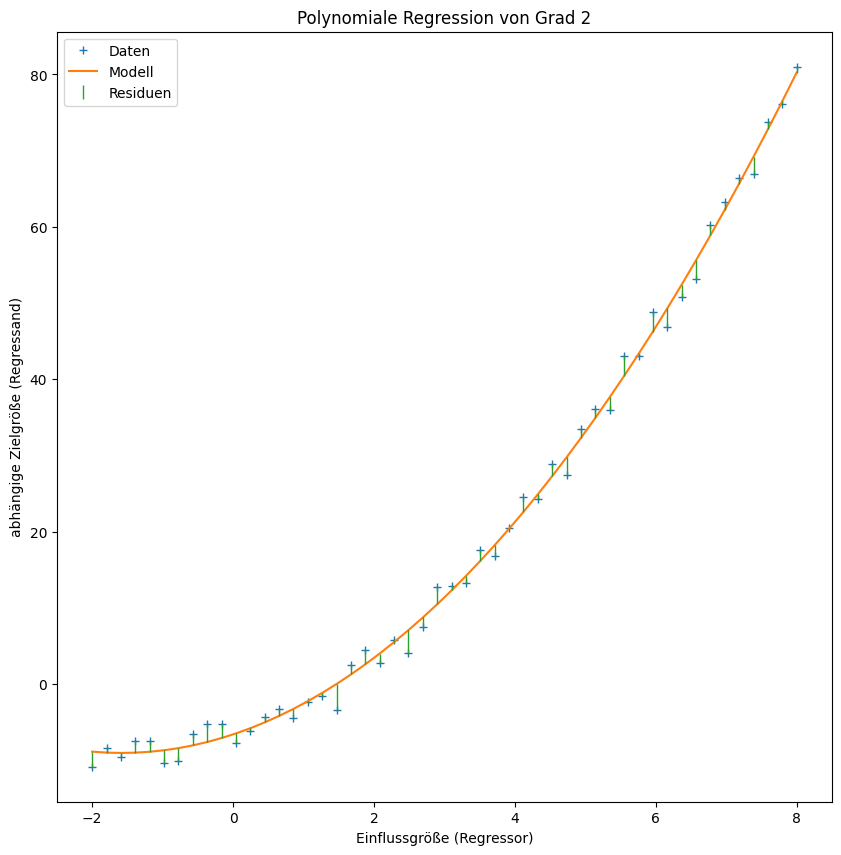

In [10]:
poly_regression_plot(x, y, 2)

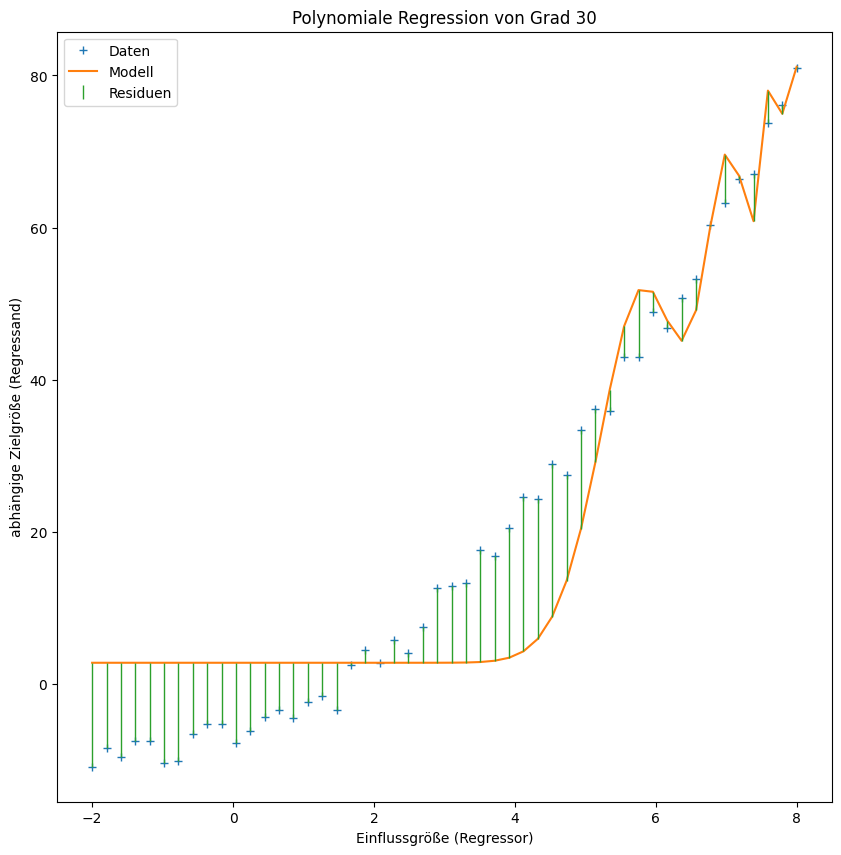

In [11]:
poly_regression_plot(x, y, 30)

Man kann ein lineares Regressionsmodell auch formulieren als

$$
P(y|X, \theta) = \mathcal{N}(w^T X, \sigma^2)
$$

bzw. mit Basisfunktionserweiterung

$$
P(y|X, \theta) = \mathcal{N}(w^T \phi(X), \sigma^2)
$$

Dabei sind $\theta_i$ die Parameter der normalverteilten Fehler $\epsilon_i$.

## Anwendungsbeispiel

Wir betrachten den [Melbourne Housing Market Datensatz von Anthony Pino](https://www.kaggle.com/datasets/anthonypino/melbourne-housing-market), CC BY-NC-SA 4.0.

Zum Einstieg putzen wir die Daten etwas.

In [12]:
import pandas as pd

df = pd.read_csv("Melbourne_housing_FULL.csv")
print(df.shape)
print(df.columns)

(34857, 21)
Index(['Suburb', 'Address', 'Rooms', 'Type', 'Price', 'Method', 'SellerG',
       'Date', 'Distance', 'Postcode', 'Bedroom2', 'Bathroom', 'Car',
       'Landsize', 'BuildingArea', 'YearBuilt', 'CouncilArea', 'Lattitude',
       'Longtitude', 'Regionname', 'Propertycount'],
      dtype='object')


In [13]:
# don't care about lat, lon here:
df = df.drop(columns=['Lattitude','Longtitude'])

# make Date a date:
df['Date'] = pd.to_datetime(df['Date'], format="%d/%m/%Y")

# Postcode is not really numeric:
df['Postcode'] = df['Postcode'].astype('category')

# make string variables categorical:
df[df.select_dtypes(['object']).columns] \
  = df[df.select_dtypes(['object']).columns].astype('category')

# Transform year built to age:
df['Age'] = 2017 - df['YearBuilt']
df = df.drop(columns='YearBuilt')

# kill faulty data:
df = df[df['BuildingArea'] != 0]
df = df[df['Age'] < 500]

# remove all suspects with missing data
df = df.dropna()

# remaining numerical variables:
numerical_columns = df.select_dtypes(['float']).columns
print(numerical_columns)

Index(['Price', 'Distance', 'Bedroom2', 'Bathroom', 'Car', 'Landsize',
       'BuildingArea', 'Propertycount', 'Age'],
      dtype='object')


In [14]:
regressor_columns = numerical_columns.drop('Price')
x = df[regressor_columns]
y = df['Price']

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test \
 = train_test_split(x, y, test_size = .20, random_state=0)

regressor = LinearRegression()
regressor.fit(x_train, y_train)
y_pred = regressor.predict(x_test)

from sklearn.metrics import r2_score
print("R^2 = %f%% der Varianz wird durch das lineare Modell erklärt"
      % (100*r2_score(y_test, y_pred)))

R^2 = 50.355458% der Varianz wird durch das lineare Modell erklärt


```{admonition} Definition
$$
R^2 = \dfrac{\sum_{i=1}^N {\left( f(x_i,\beta) - \texttt{mean}(y) \right)}^2}{\sum_{i=1}^N {\left( y_i - \texttt{mean}(y) \right)}^2}
$$

Die Größe $R^2$ wird auch **Bestimmtheitsmaß**, en. **Coefficient of determination** genannt.
```

In [15]:
cdf = pd.DataFrame(data = regressor.coef_,
                   index = regressor_columns,
                   columns = ['Coefficients'])
cdf

,Coefficients
Distance,-27377.550245
Bedroom2,109775.843441
Bathroom,264198.517970
Car,55837.834214
Landsize,23.997980
BuildingArea,2238.496526
Propertycount,-0.688488
Age,6081.670366


Interpretation:

Wenn ein Haus ein Jahr älter ist als ein anderes, ist der assoziierte Preisunterschied $5650$ (australische) Dollar. Wenn ein Haus einen Kilometer näher am Zentrum (das in Melbourne *CBD* heißt) liegt, also eine um $1$ kleinere Distance-Variable hat, ist der assoziierte Preisunterschied $27903$ Dollar.

Wir schauen uns noch Plots zur linearen Regression in den Variablen Distanz und Alter an:

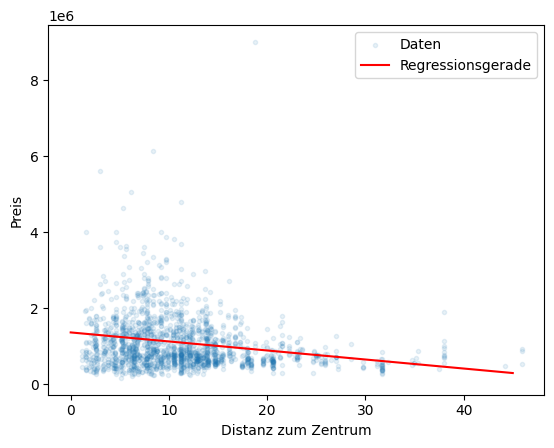

In [16]:
regressor_variable = x_train[["Distance"]]
regressor.fit(regressor_variable, y_train)
y_pred = regressor.predict(regressor_variable)

fig, ax = plt.subplots()
ax.scatter(x_test["Distance"], y_test,
           marker='.', alpha=0.1,
           label="Daten")
xs = np.arange(np.max(x_test["Distance"]))
ys = regressor.coef_[0]*xs + regressor.intercept_
ax.plot(xs, ys, color='red', label="Regressionsgerade")
ax.set_xlabel("Distanz zum Zentrum")
ax.set_ylabel("Preis")
ax.legend()
plt.show()

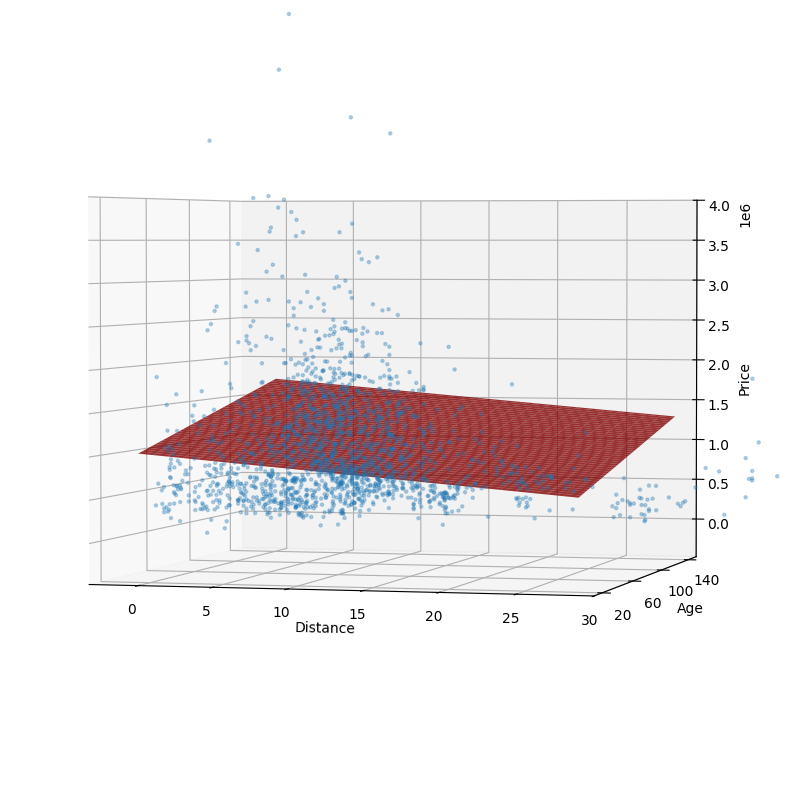

In [17]:
regressor_variable = x_train[["Distance", "Age"]]
regressor.fit(regressor_variable, y_train)
y_pred = regressor.predict(regressor_variable)

from mpl_toolkits.mplot3d import Axes3D

xs = np.arange(30)
ys = np.arange(10, np.max(x_test["Age"]))
xs, ys = np.meshgrid(xs, ys)
zs =   xs*regressor.coef_[0] \
     + ys*regressor.coef_[1] \
     + regressor.intercept_

fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(111,projection='3d')
ax.plot_surface(xs, ys, zs,
                alpha=0.8, color='red')
ax.scatter(x_test["Distance"], x_test["Age"], y_test,
           marker='.', alpha=0.3)
ax.set_zlim3d(zmax=4000000)
ax.set_xlim3d(xmax=30)
ax.set_ylim3d(ymin=10)
ax.set_xlabel("Distance")
ax.set_ylabel("Age")
ax.set_zlabel("Price")
ax.set_yticks([20,60,100,140])
ax.view_init(elev=2., azim=-75)
plt.show()

So wie diese Daten aussehen, wäre hier auch polynomiale Regression hilfreich. Wir basteln eine Pipeline zur Berechnung der polynomialen Regression.

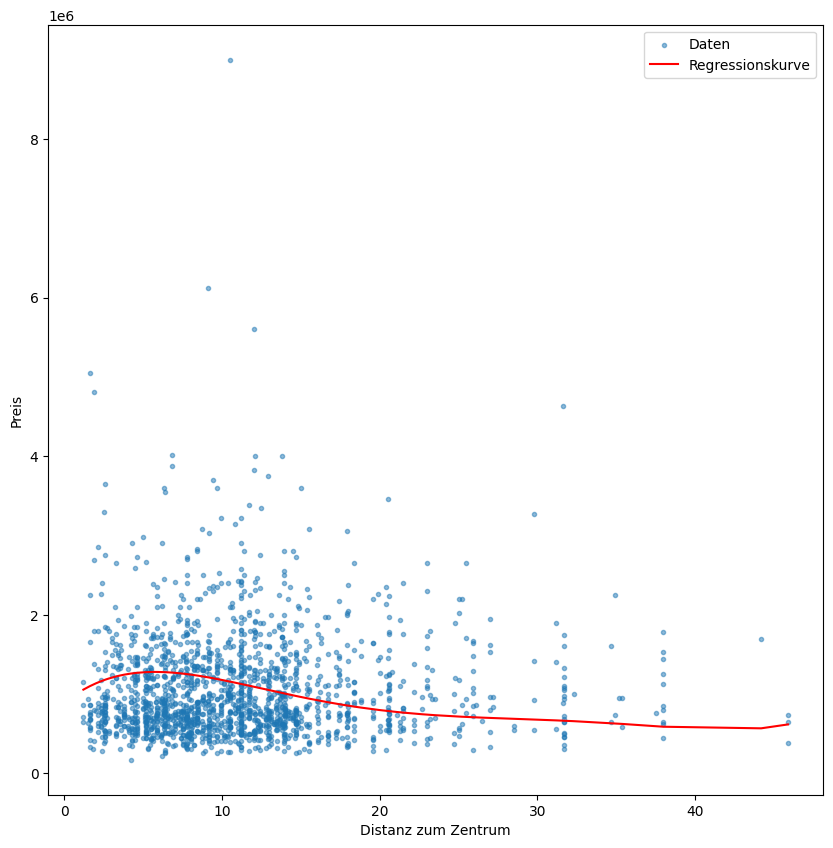

In [18]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

degree = 5

polyreg = make_pipeline(PolynomialFeatures(degree), LinearRegression())
polyreg.fit(x_train[["Distance"]], y_train)
# for plotting purposes, sort:
x_test = x_test.sort_values("Distance")
y_pred = polyreg.predict(x_test[["Distance"]])

fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(x_test["Distance"], y_test,
           marker='.', alpha=0.5,
           label="Daten")
ax.plot(x_test["Distance"], y_pred,
        color='red', label="Regressionskurve")
ax.set_xlabel("Distanz zum Zentrum")
ax.set_ylabel("Preis")
ax.legend()
plt.show()

## Regularisierung

Wenn man nur wenige Stützstellen in den Trainingsdaten hat, neigt man umso leichter zum Overfitten. Wir schauen uns das in einigen Beispielen an:

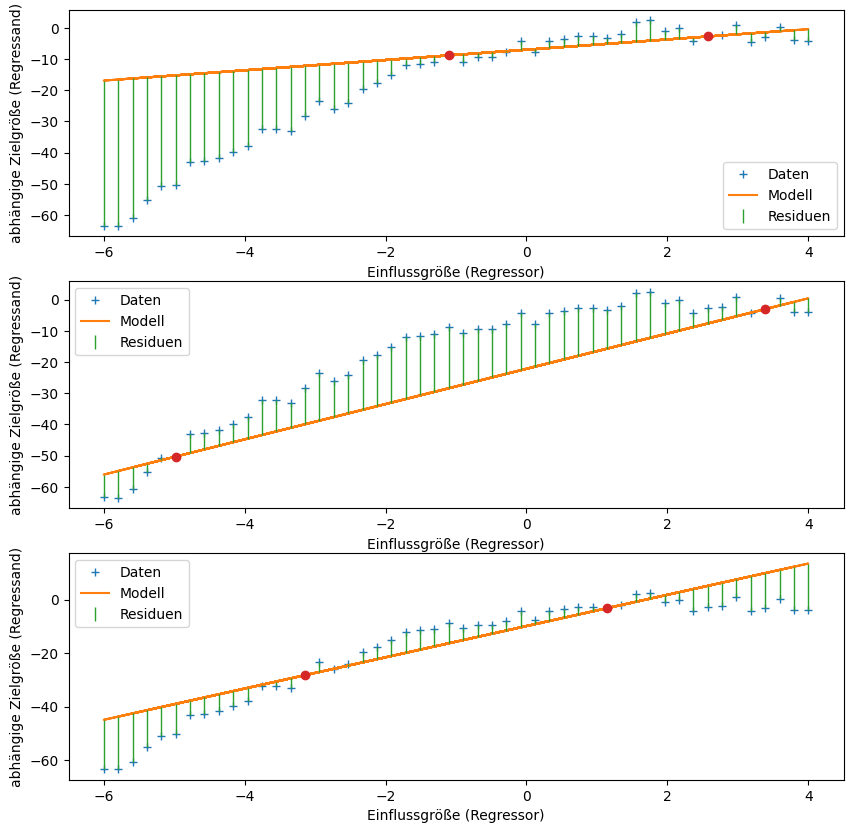

In [19]:
# generate new synthetic data:
np.random.seed(123)
x = np.linspace(-6, 4)
y = -x**2 + 4*x - 5 + np.random.uniform(-4, 4, size=x.shape)

def plot_from_small_training(ax, random_state, model=LinearRegression()):    
    # simulate having very few training data:
    x_train, x_test, y_train, y_test \
     = train_test_split(x, y, test_size = .95,
                        random_state=random_state)

    regressor = model
    regressor.fit(x_train.reshape(-1, 1), y_train)
    y_pred = regressor.predict(x_test.reshape(-1, 1))

    plot_regression(x, y, y_pred, ax, x_test, y_test)
    ax.plot(x_train, y_train, "o")

fig, axs = plt.subplots(3, 1, figsize=(10,10))
plot_from_small_training(axs[0], 3)
plot_from_small_training(axs[1], 4)
plot_from_small_training(axs[2], 5)
plt.show()

Der Trick der Regularisierung besteht nun darin, nicht *zu* gut auf die Trainingsdaten zu fitten.

Die **L2-Regularisierung**, auch als **Ridge-Regression** bekannt, besteht darin, als zusätzliches Optimierungsziel bei der Suche nach einem besten Fit für das Regressionsproblem einen Strafterm $P = \alpha \sum_{i=1}^n \beta_i^2$ zu minimieren.
Dabei ist $\alpha$ ein freier Parameter, der die Stärke der Strafe einstellt.

Der Name L2 kommt daher, dass $P$ das Quadrat der L2-Norm ist.

Es gibt auch die **L1-Regularisierung** bei der man statt $\beta_i^2$ den Summanden $|\beta_i|$ verwendet, das entspricht der L1-Norm. Man spricht auch von **Lasso-Regularisierung**.

![L1 and L2 balls, image by Wikipedia User Nicoguaro, CC BY 4.0](images/L1_and_L2_balls.svg.png)

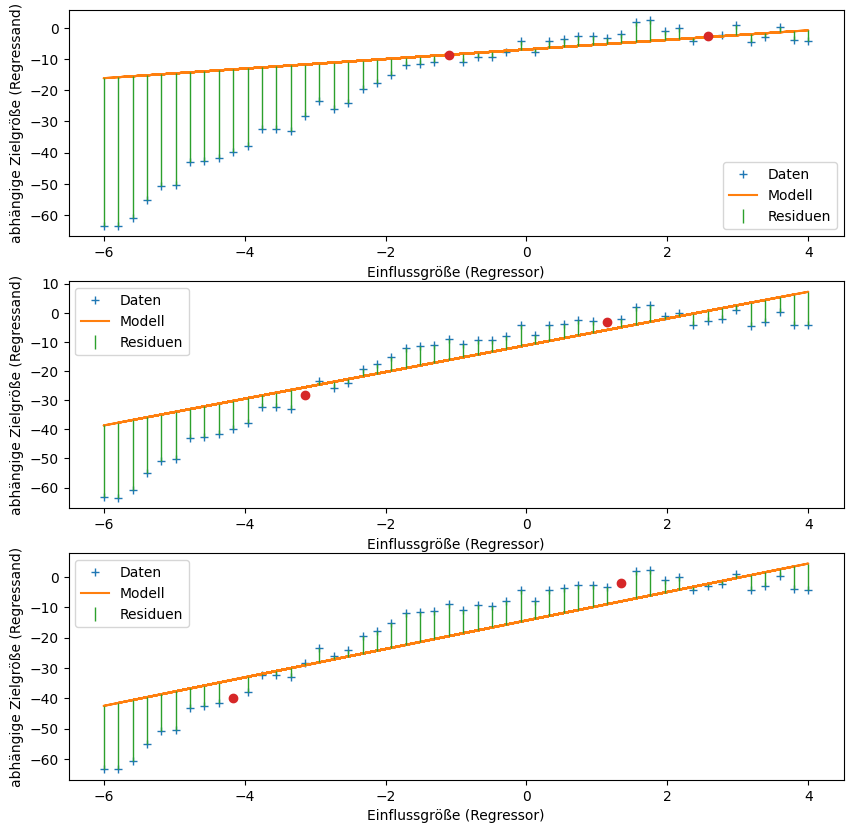

In [20]:
from sklearn.linear_model import Ridge

fig, axs = plt.subplots(3, 1, figsize=(10,10))
plot_from_small_training(axs[0], 3, model=Ridge(alpha=0.5))
plot_from_small_training(axs[1], 5, model=Ridge(alpha=2.5))
plot_from_small_training(axs[2], 10, model=Ridge(alpha=7))
plt.show()

## Zusammenfassung

Video: [Crash Course Statistics Regression](https://www.youtube.com/watch?v=WWqE7YHR4Jc)

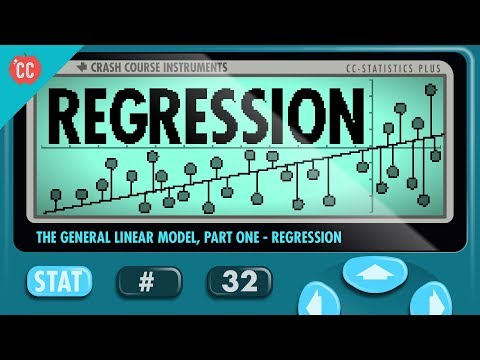

In [21]:
from IPython.display import YouTubeVideo
YouTubeVideo('WWqE7YHR4Jc')